# Zadanie 1

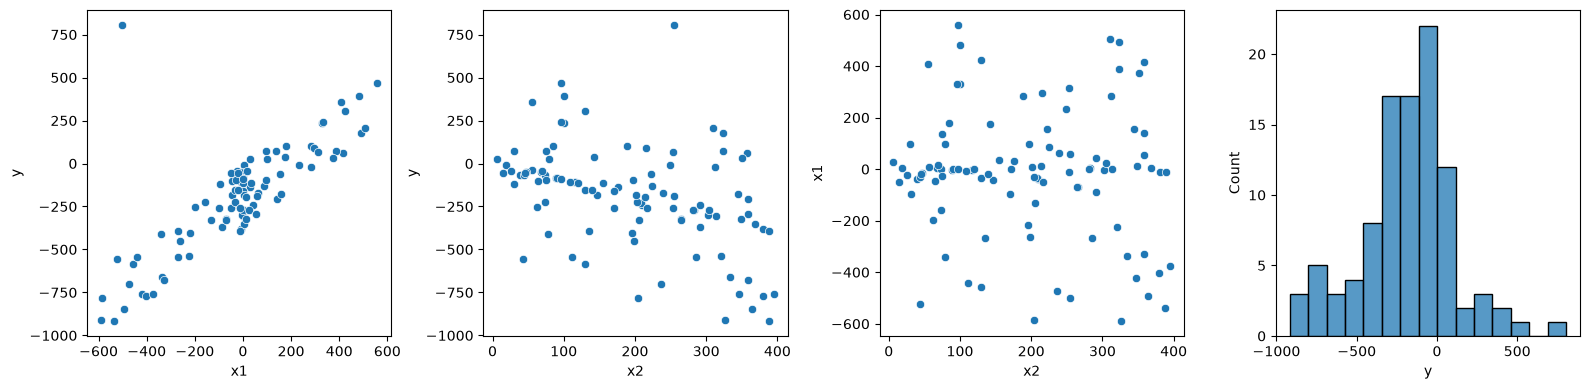

Współczynnik korelacji Perasona dla wykresu x1 od x2: -0.10331575849372848
Współczynnik korelacji Perasona dla wykresu y od x2: -0.44093412497640655
Współczynnik korelacji Perasona dla wykresu y od x1: 0.7807075119131058


In [49]:
# Zależność y od x1 lub x2 oraz x1 od x2
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("data1.csv");
f, axs = plt.subplots(1, 4, figsize=(16, 4))
sns.scatterplot(data=df, x="x1", y="y", ax=axs[0])
sns.scatterplot(data=df, x="x2", y="y", ax=axs[1])
sns.scatterplot(data=df, x="x2", y="x1", ax=axs[2])
sns.histplot(data=df, x="y")
f.tight_layout()
plt.show()

# Jaki jest współczynnik korealcji Perasona dla wykresu x1 od x2?
print("Współczynnik korelacji Perasona dla wykresu x1 od x2:", df["x2"].corr(df["x1"], method='pearson'))
print("Współczynnik korelacji Perasona dla wykresu y od x2:", df["x2"].corr(df["y"], method='pearson'))
print("Współczynnik korelacji Perasona dla wykresu y od x1:", df["x1"].corr(df["y"], method='pearson'))

### Wnioski: 
- x1, x2 są niezależne liniowo
- Widać powiązanie y z x1
- O wiele gorzej, ale widać powiązanie y z x2
- W obu wykresach y od x1 oraz y od x2 występują skrajne outliery, będzie trzeba to uwzględnić przy wyborze funkcji straty
- Możliwe że warto będzie porównać 3 wersje modelu: wersja z samą cechą x1, wersja z obiema cechami oraz wersja z cechą x1
- Istnieją pojedyńcze bardzo duże odchylenia `y` - możliwe że warto się ich pozbyć

### Sprzątanie danych
Możemy w preprocessingu usunąć 1% outlierów z `y` aby mieć czystsze dane do nauki

In [98]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression

def preprocess_data(X_train, y_train):
    df_temp = X_train.copy()
    df_temp["y"] = y_train
    low_y, high_y = df_temp["y"].quantile(0.01), df_temp["y"].quantile(0.99)

    df_filtered = df_temp[
        (df_temp["y"] >= low_y) & (df_temp["y"] <= high_y)
    ]
    
    X_clean = df_filtered.drop(columns=["y"])
    y_clean = df_filtered["y"]

    return X_clean, y_clean

df = pd.read_csv("data1.csv")

X = df.drop(columns=["y"])
y = df["y"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

X_train, y_train = preprocess_data(X_train, y_train)

model = LinearRegression()
model.fit(X_train, y_train)
print(f"Znaleziona prosta: y = {model.intercept_:.2f} + {model.coef_[0]:.2f}x_1 + {model.coef_[1]:.2f}x_2")
y_val_pred = model.predict(X_val)
print(f"MAE Modelu z cechami x1, x2 (po usunieciu outlierów): {mean_absolute_error(y_val, y_val_pred):.4f}")
print(f"MSE Modelu z cechami x1, x2 (po usunieciu outlierów): {mean_squared_error(y_val, y_val_pred):.4f}")

Znaleziona prosta: y = 7.61 + 1.00x_1 + -1.00x_2
MAE Modelu z cechami x1, x2 (po usunieciu outlierów): 0.5886
MSE Modelu z cechami x1, x2 (po usunieciu outlierów): 0.4776


### Teraz porównajmy co by się stało gdyby pozbyć się x2 z modelu

In [69]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression

def preprocess_data(X_train, y_train):
    df_temp = X_train.copy()
    df_temp["y"] = y_train
    low_y, high_y = df_temp["y"].quantile(0.01), df_temp["y"].quantile(0.99)

    df_filtered = df_temp[
        (df_temp["y"] >= low_y) & (df_temp["y"] <= high_y)
    ]
    
    X_clean = df_filtered.drop(columns=["y"])
    y_clean = df_filtered["y"]

    return X_clean, y_clean

df = pd.read_csv("data1.csv")

X = df[["x1"]]
y = df["y"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

X_train, y_train = preprocess_data(X_train, y_train)

model = LinearRegression()
model.fit(X_train, y_train)
print(f"Znaleziona prosta: y = {model.intercept_:.2f} + {model.coef_[0]:.2f}x_1")
y_val_pred = model.predict(X_val)
print(f"MAE Modelu z cechami x1 (po usunieciu outlierów): {mean_absolute_error(y_val, y_val_pred):.4f}")
print(f"MSE Modelu z cechami x1 (po usunieciu outlierów): {mean_squared_error(y_val, y_val_pred):.4f}")

Znaleziona prosta: y = -193.24 + 1.00x_1
MAE Modelu z cechami x1 (po usunieciu outlierów): 116.0044
MSE Modelu z cechami x1 (po usunieciu outlierów): 15650.9748


### Wniosek - i tak lepiej jest użyć obu cech
Pomysł: czy połączenie cechy x1 i x2 w nową ceche zminimalizuje błąd bardziej?

### Wykresy różnych wersji nowych cech

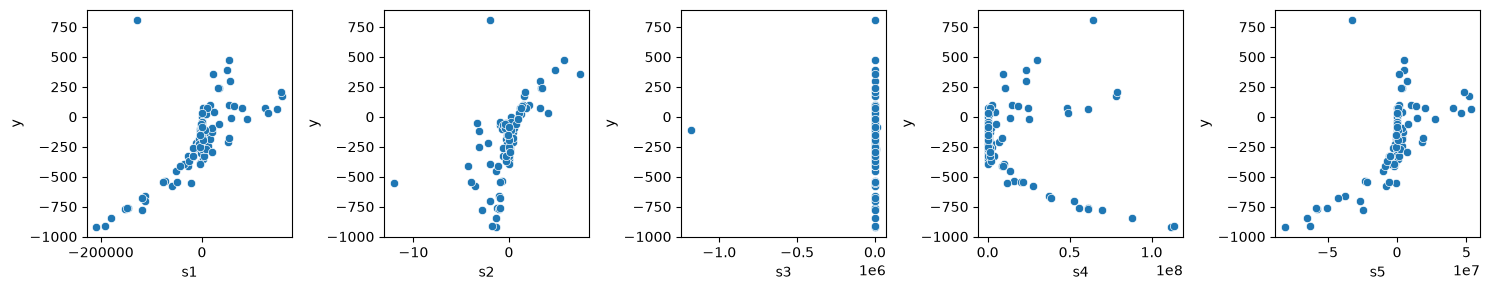

In [97]:
# (Wykresy) Zależność y od x1 lub x2 oraz x1 od x2
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("data1.csv");
df["s1"] = df["x1"] * df["x2"]
df["s2"] = df["x1"] / (df["x2"] + 1e-12)
df["s3"] = df["x2"] / (df["x1"] + 1e-12)
df["s4"] = df["x1"] * df["x1"] * df["x2"]
df["s5"] = df["x1"] * df["x2"] * df["x2"]

f, axs = plt.subplots(1, 5, figsize=(15, 3))
sns.scatterplot(data=df, x="s1", y="y", ax=axs[0])
sns.scatterplot(data=df, x="s2", y="y", ax=axs[1])
sns.scatterplot(data=df, x="s3", y="y", ax=axs[2])
sns.scatterplot(data=df, x="s4", y="y", ax=axs[3])
sns.scatterplot(data=df, x="s5", y="y", ax=axs[4])
f.tight_layout()
plt.show()

In [77]:
# Test nowej cechy s = x1 * x2
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression

def preprocess_data(X_train, y_train):
    df_temp = X_train.copy()
    df_temp["y"] = y_train
    low_y, high_y = df_temp["y"].quantile(0.01), df_temp["y"].quantile(0.99)

    df_filtered = df_temp[
        (df_temp["y"] >= low_y) & (df_temp["y"] <= high_y)
    ]
    
    X_clean = df_filtered.drop(columns=["y"])
    y_clean = df_filtered["y"]

    return X_clean, y_clean

df = pd.read_csv("data1.csv")
df["s"] = df["x1"] * df["x2"]

X = df.drop(columns=["y"])
y = df["y"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

X_train, y_train = preprocess_data(X_train, y_train)

model = LinearRegression()
model.fit(X_train, y_train)
print(f"Znaleziona prosta: y = {model.intercept_:.2f} + {model.coef_[0]:.2f}x_1 + {model.coef_[1]:.2f}x_2 + {model.coef_[2]:.2f}x_1 * x_2")
y_val_pred = model.predict(X_val)
print(f"MAE Modelu z cechami x1, x2, x1 * x2 (po usunieciu outlierów): {mean_absolute_error(y_val, y_val_pred):.4f}")
print(f"MSE Modelu z cechami x1, x2, x1 * x2 (po usunieciu outlierów): {mean_squared_error(y_val, y_val_pred):.4f}")

Znaleziona prosta: y = 7.58 + 1.00x_1 + -1.00x_2 + 0.00x_1 * x_2
MAE Modelu z cechami x1, x2, x1 * x2 (po usunieciu outlierów): 0.6604
MSE Modelu z cechami x1, x2, x1 * x2 (po usunieciu outlierów): 0.5682


In [95]:
# Test nowej cechy s = x1 / x2
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression

def preprocess_data(X_train, y_train):
    df_temp = X_train.copy()
    df_temp["y"] = y_train
    low_y, high_y = df_temp["y"].quantile(0.01), df_temp["y"].quantile(0.99)

    df_filtered = df_temp[
        (df_temp["y"] >= low_y) & (df_temp["y"] <= high_y)
    ]
    
    X_clean = df_filtered.drop(columns=["y"])
    y_clean = df_filtered["y"]

    return X_clean, y_clean

df = pd.read_csv("data1.csv")
df["s"] = df["x1"] / (df["x2"] + 1e-10)

X = df.drop(columns=["y"])
y = df["y"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

X_train, y_train = preprocess_data(X_train, y_train)

model = LinearRegression()
model.fit(X_train, y_train)
print(f"Znaleziona prosta: y = {model.intercept_:.2f} + {model.coef_[0]:.2f}x_1 + {model.coef_[1]:.2f}x_2 + {model.coef_[2]:.2f}x_1 * x_2")
y_val_pred = model.predict(X_val)
print(f"MAE Modelu z cechami x1, x2, x1 * x2 (po usunieciu outlierów): {mean_absolute_error(y_val, y_val_pred):.4f}")
print(f"MSE Modelu z cechami x1, x2, x1 * x2 (po usunieciu outlierów): {mean_squared_error(y_val, y_val_pred):.4f}")

Znaleziona prosta: y = 7.56 + 1.00x_1 + -1.00x_2 + -0.14x_1 * x_2
MAE Modelu z cechami x1, x2, x1 * x2 (po usunieciu outlierów): 0.6846
MSE Modelu z cechami x1, x2, x1 * x2 (po usunieciu outlierów): 0.5950


In [100]:
# Test nowej cechy s = x2 / x1
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression

def preprocess_data(X_train, y_train):
    df_temp = X_train.copy()
    df_temp["y"] = y_train
    low_y, high_y = df_temp["y"].quantile(0.01), df_temp["y"].quantile(0.99)

    df_filtered = df_temp[
        (df_temp["y"] >= low_y) & (df_temp["y"] <= high_y)
    ]
    
    X_clean = df_filtered.drop(columns=["y"])
    y_clean = df_filtered["y"]

    return X_clean, y_clean

df = pd.read_csv("data1.csv")
df["s"] = df["x2"] / (df["x1"] + 1e-12)

X = df.drop(columns=["y"])
y = df["y"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

X_train, y_train = preprocess_data(X_train, y_train)

model = LinearRegression()
model.fit(X_train, y_train)
print(f"Znaleziona prosta: y = {model.intercept_:.2f} + {model.coef_[0]:.2f}x_1 + {model.coef_[1]:.2f}x_2 + {model.coef_[2]:.2f}x_2 / x_1^2")
y_val_pred = model.predict(X_val)
print(f"MAE Modelu z cechami x1, x2, x1 * x2 (po usunieciu outlierów): {mean_absolute_error(y_val, y_val_pred):.4f}")
print(f"MSE Modelu z cechami x1, x2, x1 * x2 (po usunieciu outlierów): {mean_squared_error(y_val, y_val_pred):.4f}")

Znaleziona prosta: y = 7.67 + 1.00x_1 + -1.00x_2 + 0.00x_2 / x_1^2
MAE Modelu z cechami x1, x2, x1 * x2 (po usunieciu outlierów): 0.5843
MSE Modelu z cechami x1, x2, x1 * x2 (po usunieciu outlierów): 0.4697


## Konkluzja
Jedyne co miało sens to czyszczenie outlierów `y` oraz dodanie nowej cechy `s = x2 / x1`. Ale nie możemy dodawać nowej kolumny w tym zadaniu więc najlepsze co możemy to po porstu usuną

In [103]:
# Test modelu na danych testowych
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression

def preprocess_data(X_train, y_train):
    df_temp = X_train.copy()
    df_temp["y"] = y_train
    low_y, high_y = df_temp["y"].quantile(0.01), df_temp["y"].quantile(0.99)

    df_filtered = df_temp[
        (df_temp["y"] >= low_y) & (df_temp["y"] <= high_y)
    ]
    
    X_clean = df_filtered.drop(columns=["y"])
    y_clean = df_filtered["y"]

    return X_clean, y_clean

df = pd.read_csv("data1.csv")
df["s"] = df["x2"] / (df["x1"] + 1e-12)

X = df.drop(columns=["y"])
y = df["y"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

X_train, y_train = preprocess_data(X_train, y_train)

model = LinearRegression()
model.fit(X_train, y_train)
print(f"Znaleziona prosta: y = {model.intercept_:.2f} + {model.coef_[0]:.2f}x_1 + {model.coef_[1]:.2f}x_2 + {model.coef_[2]:.2f}x_2 / x_1^2")
y_test_pred = model.predict(X_test)
print(f"MAE Modelu z cechami x1, x2, x1 * x2 (po usunieciu outlierów): {mean_absolute_error(y_test, y_test_pred):.4f}")
print(f"MSE Modelu z cechami x1, x2, x1 * x2 (po usunieciu outlierów): {mean_squared_error(y_test, y_test_pred):.4f}")

Znaleziona prosta: y = 7.67 + 1.00x_1 + -1.00x_2 + 0.00x_2 / x_1^2
MAE Modelu z cechami x1, x2, x1 * x2 (po usunieciu outlierów): 0.9330
MSE Modelu z cechami x1, x2, x1 * x2 (po usunieciu outlierów): 1.2524
